# Reddit Reply Networks - EDA

## Setup

The code lives in the python files next to this notebook:

- `reply_network_analyzer.py` - features for one subreddit JSON file
- `eda_datasets.py` - builds the datasets (or loads them from `eda_outputs/`)
- `eda_summaries.py` - grouping and summary tables
- `eda_plots.py` - plots

In [1]:
import numpy as np
import pandas as pd

from eda_datasets import EdaDatasets
from eda_summaries import EdaSummaries
from eda_plots import EdaPlots, FIGURE_DIR

# set to True to recompute the datasets instead of loading them from eda_outputs/
REBUILD = False

datasets = EdaDatasets(rebuild=REBUILD)

## User activity

### Build user activity dataset (or load from csv)

In [2]:
activity_df = datasets.user_activity()

### Dataset overview

In [3]:
print("Number of user-month observations:", f"{len(activity_df):,}")
print("Number of unique subreddits:", activity_df["subreddit"].nunique())
print("Number of unique users:", activity_df["user"].nunique())

print("\nFirst 10 observations:")
print(activity_df.head(10))

Number of user-month observations: 40,050,308


Number of unique subreddits: 2046


Number of unique users: 3558983

First 10 observations:
   subreddit  month                user  replies_sent  \
0  2007scape      1            ModReach            27   
1  2007scape      1         cartman2468             1   
2  2007scape      1  _CreativeNameHere_             1   
3  2007scape      1           BigLou420             1   
4  2007scape      1              Abstre             3   
5  2007scape      1           aflackguy             2   
6  2007scape      1            WeaselWJ             3   
7  2007scape      1          Indica_Joe             1   
8  2007scape      1          soupdahero             1   
9  2007scape      1        AstuteAndrew             1   

   unique_users_replied_to  replies_received  unique_users_who_replied  \
0                       27                39                        39   
1                        1                 0                         0   
2                        1                 1                         1   
3                   

### Summary statistics

In [4]:
#dataset summary statistics
print("\nSummary statistics:")
print(
    activity_df[
        [
            "replies_sent",
            "unique_users_replied_to",
            "replies_received",
            "unique_users_who_replied",
            "total_interactions"
        ]
    ].describe().map(lambda x: f"{x:,.2f}")
)


Summary statistics:


        replies_sent unique_users_replied_to replies_received  \
count  40,050,308.00           40,050,308.00    40,050,308.00   
mean            3.42                    3.42             3.14   
std             8.96                    8.96             9.42   
min             1.00                    1.00             0.00   
25%             1.00                    1.00             0.00   
50%             1.00                    1.00             1.00   
75%             3.00                    3.00             3.00   
max         2,350.00                2,350.00         2,173.00   

      unique_users_who_replied total_interactions  
count            40,050,308.00      40,050,308.00  
mean                      3.14               6.55  
std                       9.42              17.77  
min                       0.00               1.00  
25%                       0.00               1.00  
50%                       1.00               3.00  
75%                       3.00               6.00 

### Distribution of replies sent

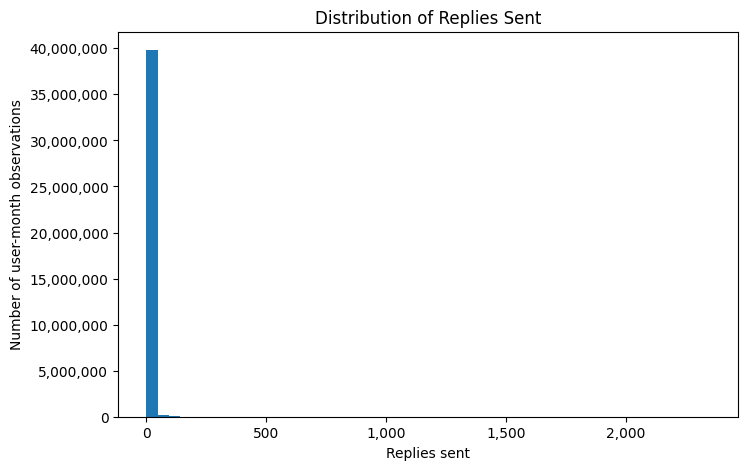

In [5]:
EdaPlots.histogram(
    activity_df["replies_sent"],
    xlabel="Replies sent",
    ylabel="Number of user-month observations",
    title="Distribution of Replies Sent",
    plain_axis="both",
    thousands_axes="xy"
)

### Distribution of replies sent (log)

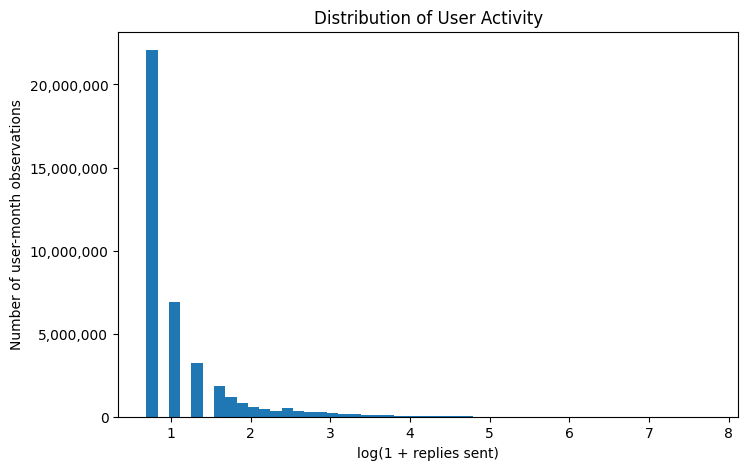

In [6]:
EdaPlots.histogram(
    np.log1p(activity_df["replies_sent"]),
    xlabel="log(1 + replies sent)",
    ylabel="Number of user-month observations",
    title="Distribution of User Activity",
    plain_axis="y",
    thousands_axes="y"
)

## User activity & return

### Build return dataset (or load from csv)

In [7]:
return_df = datasets.user_return()

print(return_df.head())
print("\nOverall return rate:")
print(return_df["returned_next_month"].mean())

   subreddit  month                user  returned_next_month
0  2007scape      1            ModReach                    1
1  2007scape      1         cartman2468                    0
2  2007scape      1  _CreativeNameHere_                    0
3  2007scape      1           BigLou420                    0
4  2007scape      1              Abstre                    1

Overall return rate:
0.36388026963043035


### Merge activity and return

In [8]:
user_month_df = datasets.user_month()

print("Final observations:", len(user_month_df))
print(user_month_df.head())

Final observations: 36031393
   subreddit  month                user  replies_sent  \
0  2007scape      1            ModReach            27   
1  2007scape      1         cartman2468             1   
2  2007scape      1  _CreativeNameHere_             1   
3  2007scape      1           BigLou420             1   
4  2007scape      1              Abstre             3   

   unique_users_replied_to  replies_received  unique_users_who_replied  \
0                       27                39                        39   
1                        1                 0                         0   
2                        1                 1                         1   
3                        1                 0                         0   
4                        3                 3                         3   

   total_interactions  returned_next_month  
0                  66                    1  
1                   1                    0  
2                   2                    0  
3  

### Return rate by activity group

In [9]:
activity_return = datasets.activity_return()

print(activity_return)

  activity_group     users  return_rate  return_rate_percent
0        1 reply  19860469     0.222800            22.280028
1    11+ replies   1953954     0.877027            87.702730
2    2–3 replies   9139852     0.403481            40.348148
3   4–10 replies   5077118     0.646974            64.697393


### Plot: next-month return by activity group

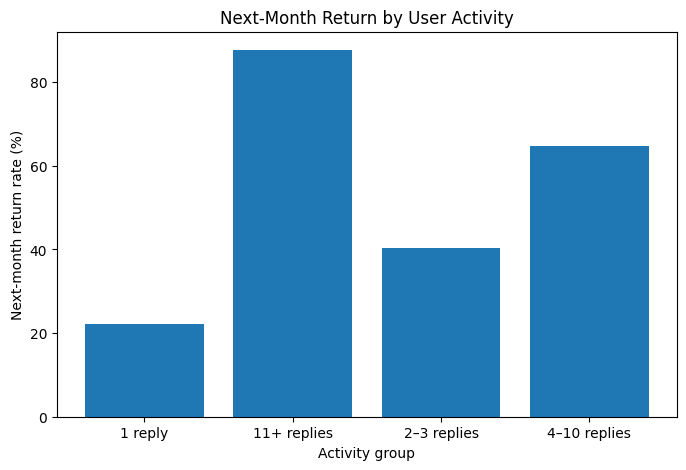

In [10]:
EdaPlots.bar(
    activity_return["activity_group"].astype(str),
    activity_return["return_rate_percent"],
    xlabel="Activity group",
    ylabel="Next-month return rate (%)",
    title="Next-Month Return by User Activity"
)

## Community & Network

### Build community dataset (or load from csv)

In [11]:
community_df = datasets.community()

print("Number of subreddit-month observations:", len(community_df))
print(community_df.head())
print(community_df['edges'].sum())

Number of subreddit-month observations: 22506
   subreddit  month  active_users  edges   density  average_out_degree  \
0  2007scape      1          1896   7380  0.002054            3.892405   
1  2007scape      2          1812   6954  0.002119            3.837748   
2  2007scape      3          1904   8090  0.002233            4.248950   
3  2007scape      4          2293  10743  0.002044            4.685129   
4  2007scape      5          3318  15329  0.001393            4.619952   

   average_in_degree  
0           3.892405  
1           3.837748  
2           4.248950  
3           4.685129  
4           4.619952  
136829959


### Community size summary

In [12]:
#community size
print(
    community_df[
        [
            "active_users",
            "edges",
            "density",
            "average_out_degree",
            "average_in_degree"
        ]
    ].describe()
)

        active_users          edges       density  average_out_degree  \
count   22506.000000   22506.000000  22506.000000        22506.000000   
mean     2093.074425    6079.710255      0.005342            2.462413   
std      7680.662385   23174.900763      0.015368            1.673313   
min        11.000000      34.000000      0.000015            0.714286   
25%       350.000000     626.000000      0.001503            1.488110   
50%       640.000000    1323.000000      0.003140            1.984123   
75%      1419.750000    3535.750000      0.005535            2.881421   
max    171234.000000  443538.000000      0.497368           31.938374   

       average_in_degree  
count       22506.000000  
mean            2.462413  
std             1.673313  
min             0.714286  
25%             1.488110  
50%             1.984123  
75%             2.881421  
max            31.938374  


### Distribution of community size

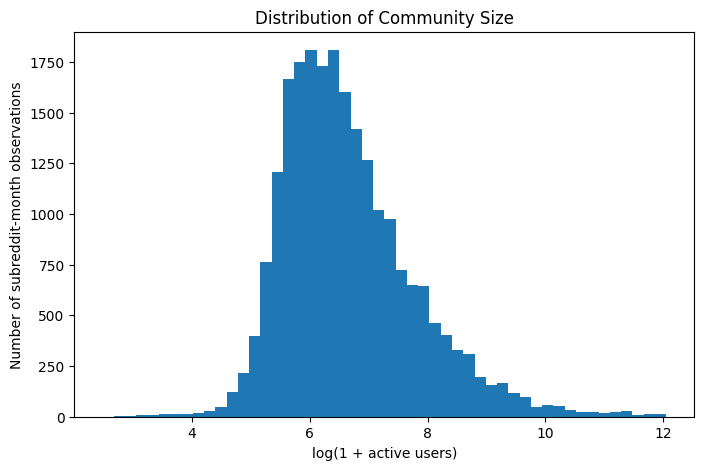

In [13]:
EdaPlots.histogram(
    np.log1p(community_df["active_users"]),
    xlabel="log(1 + active users)",
    ylabel="Number of subreddit-month observations",
    title="Distribution of Community Size"
)

### Community size & return rate

In [14]:
community_return_df = datasets.community_return()

print(community_return_df.head())

   subreddit  month  users  return_rate  active_users  edges   density  \
0  2007scape      1   1543     0.443940          1896   7380  0.002054   
1  2007scape      2   1483     0.484154          1812   6954  0.002119   
2  2007scape      3   1600     0.484375          1904   8090  0.002233   
3  2007scape      4   1915     0.509661          2293  10743  0.002044   
4  2007scape      5   2802     0.442184          3318  15329  0.001393   

   average_out_degree  average_in_degree  
0            3.892405           3.892405  
1            3.837748           3.837748  
2            4.248950           4.248950  
3            4.685129           4.685129  
4            4.619952           4.619952  


### Plot: community size vs return rate

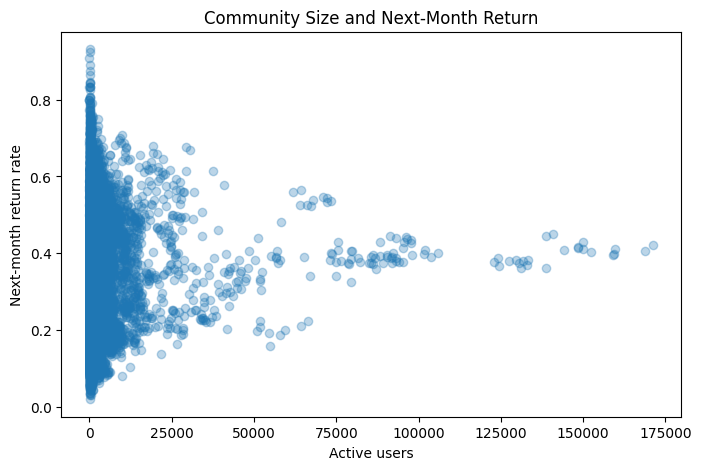

In [15]:
EdaPlots.scatter(
    community_return_df["active_users"],
    community_return_df["return_rate"],
    xlabel="Active users",
    ylabel="Next-month return rate",
    title="Community Size and Next-Month Return"
)

### Plot: network density vs return rate

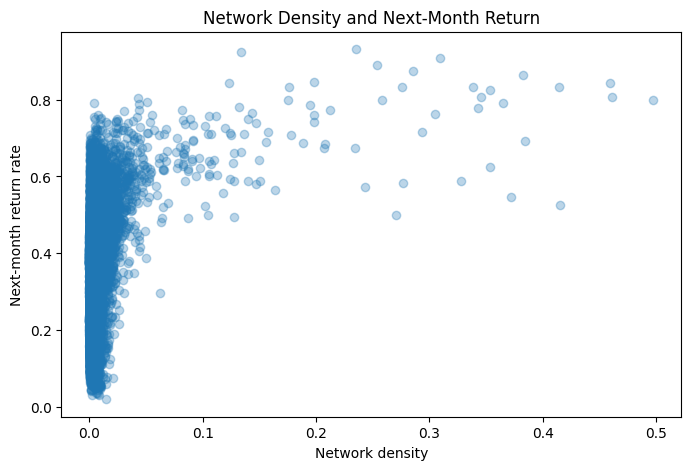

In [16]:
EdaPlots.scatter(
    community_return_df["density"],
    community_return_df["return_rate"],
    xlabel="Network density",
    ylabel="Next-month return rate",
    title="Network Density and Next-Month Return"
)

## Time / network evolution

### Monthly network summary

In [17]:
monthly_summary = datasets.monthly_summary()

print(monthly_summary)

    month  mean_active_users  median_active_users   mean_edges  mean_density  \
0       1        1977.335288                583.0  5521.878299      0.005751   
1       2        1971.497067                591.0  5597.472630      0.005582   
2       3        1999.147605                616.5  5699.481427      0.005516   
3       4        2020.955034                638.0  5805.437928      0.005412   
4       5        2006.059629                611.5  5675.678886      0.005456   
5       6        2033.614858                623.5  5904.450635      0.005310   
6       7        2143.478006                661.0  6324.735582      0.005158   
7       8        2154.293255                674.5  6313.221896      0.005359   
8       9        2193.401271                671.0  6584.284946      0.005105   
9      10        2223.755132                689.0  6637.876344      0.005060   
10     11        2300.281525                702.0  6812.294233      0.005058   

    mean_out_degree  mean_in_degree  
0

### Plot: community size over time

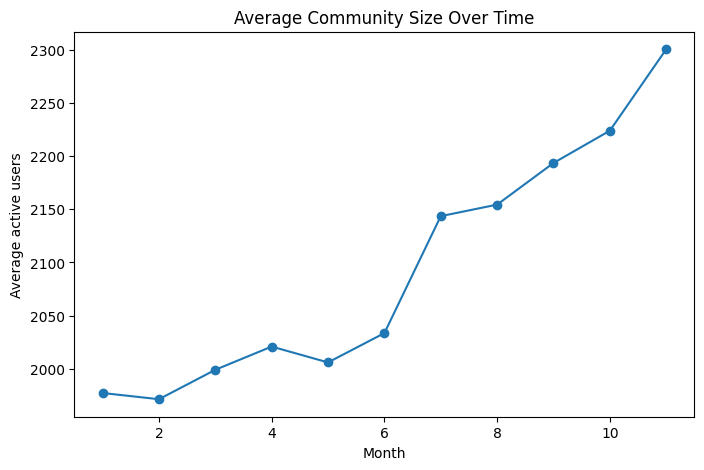

In [18]:
EdaPlots.line(
    monthly_summary["month"],
    monthly_summary["mean_active_users"],
    xlabel="Month",
    ylabel="Average active users",
    title="Average Community Size Over Time"
)

### Plot: density over time

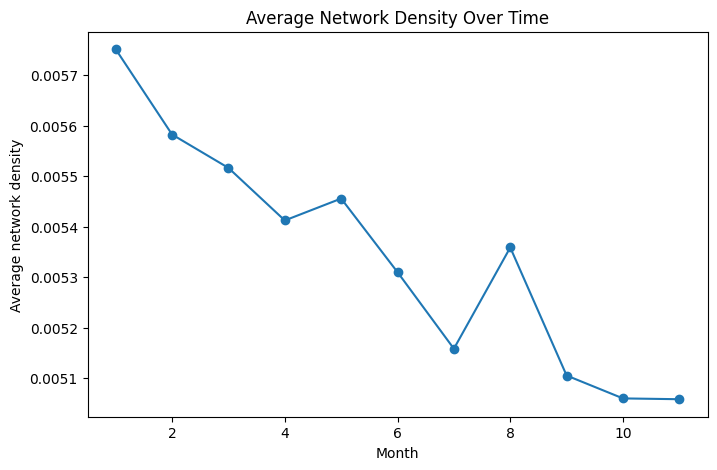

In [19]:
EdaPlots.line(
    monthly_summary["month"],
    monthly_summary["mean_density"],
    xlabel="Month",
    ylabel="Average network density",
    title="Average Network Density Over Time"
)

### Return rate by month

In [20]:
return_by_month = datasets.return_by_month()

print(return_by_month)

   month  observations  return_rate  return_rate_percent
0      1       3427086     0.360800            36.079952
1      2       3418804     0.365797            36.579722
2      3       3461984     0.363350            36.334974
3      4       3502808     0.357668            35.766791
4      5       3482613     0.360033            36.003311
5      6       3535150     0.368105            36.810461
6      7       3737653     0.360502            36.050243
7      8       3754851     0.363161            36.316141
8      9       3828833     0.367673            36.767339
9     10       3881611     0.370802            37.080197


### Plot: return rate over time

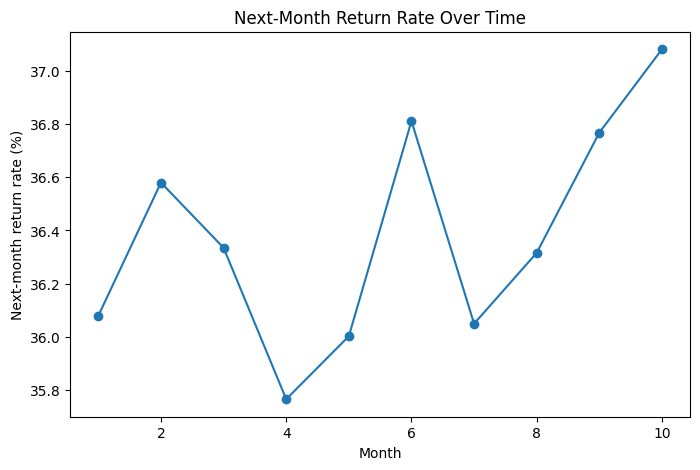

In [21]:
EdaPlots.line(
    return_by_month["month"],
    return_by_month["return_rate_percent"],
    xlabel="Month",
    ylabel="Next-month return rate (%)",
    title="Next-Month Return Rate Over Time"
)

## User degree analysis

### Summary statistics for user-level degree measures

In [22]:
degree_columns = [
    "replies_sent",
    "replies_received",
    "unique_users_replied_to",
    "unique_users_who_replied"
]

print("User-level degree statistics")
print("============================")

print(
    activity_df[degree_columns]
    .describe()
    .map(lambda x: f"{x:,.2f}")
)

User-level degree statistics


        replies_sent replies_received unique_users_replied_to  \
count  40,050,308.00    40,050,308.00           40,050,308.00   
mean            3.42             3.14                    3.42   
std             8.96             9.42                    8.96   
min             1.00             0.00                    1.00   
25%             1.00             0.00                    1.00   
50%             1.00             1.00                    1.00   
75%             3.00             3.00                    3.00   
max         2,350.00         2,173.00                2,350.00   

      unique_users_who_replied  
count            40,050,308.00  
mean                      3.14  
std                       9.42  
min                       0.00  
25%                       0.00  
50%                       1.00  
75%                       3.00  
max                   2,173.00  


### Compare total replies with unique interaction partners

In [23]:
outgoing_difference = (
    activity_df["replies_sent"]
    - activity_df["unique_users_replied_to"]
)

incoming_difference = (
    activity_df["replies_received"]
    - activity_df["unique_users_who_replied"]
)

print("Outgoing interactions")
print("=====================")
print(
    "Observations where replies sent > unique users replied to:",
    f"{(outgoing_difference > 0).sum():,}"
)
print(
    "Maximum difference:",
    f"{outgoing_difference.max():,}"
)

print("\nIncoming interactions")
print("=====================")
print(
    "Observations where replies received > unique users who replied:",
    f"{(incoming_difference > 0).sum():,}"
)
print(
    "Maximum difference:",
    f"{incoming_difference.max():,}"
)

Outgoing interactions
Observations where replies sent > unique users replied to: 0
Maximum difference: 0

Incoming interactions
Observations where replies received > unique users who replied: 0
Maximum difference: 0


### Distribution of replies received

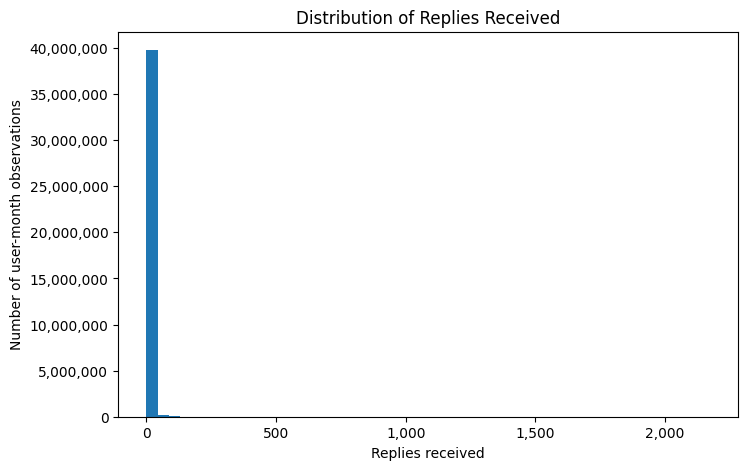

In [24]:
EdaPlots.histogram(
    activity_df["replies_received"],
    xlabel="Replies received",
    ylabel="Number of user-month observations",
    title="Distribution of Replies Received",
    plain_axis="both",
    thousands_axes="xy"
)

### Distribution of unique users replied to

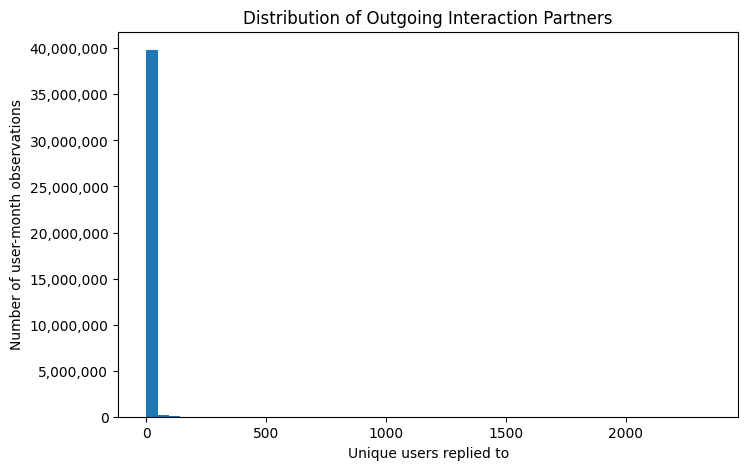

In [25]:
EdaPlots.histogram(
    activity_df["unique_users_replied_to"],
    xlabel="Unique users replied to",
    ylabel="Number of user-month observations",
    title="Distribution of Outgoing Interaction Partners",
    plain_axis="both",
    thousands_axes="y"
)

### Distribution of unique users who replied

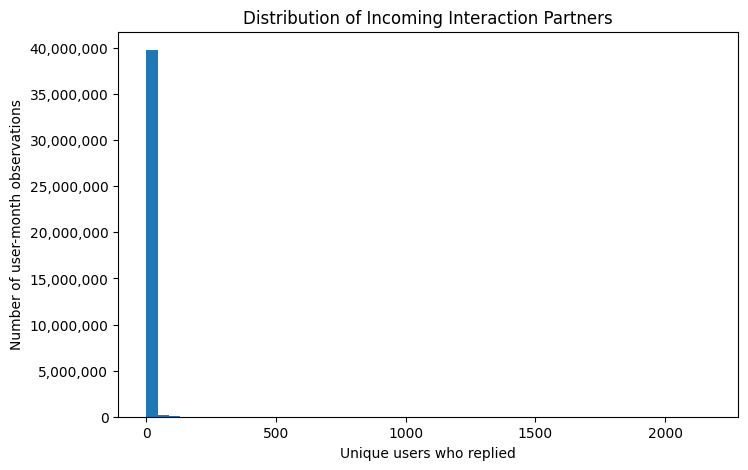

In [26]:
EdaPlots.histogram(
    activity_df["unique_users_who_replied"],
    xlabel="Unique users who replied",
    ylabel="Number of user-month observations",
    title="Distribution of Incoming Interaction Partners",
    plain_axis="both",
    thousands_axes="y"
)

### Log-transformed user degree distributions

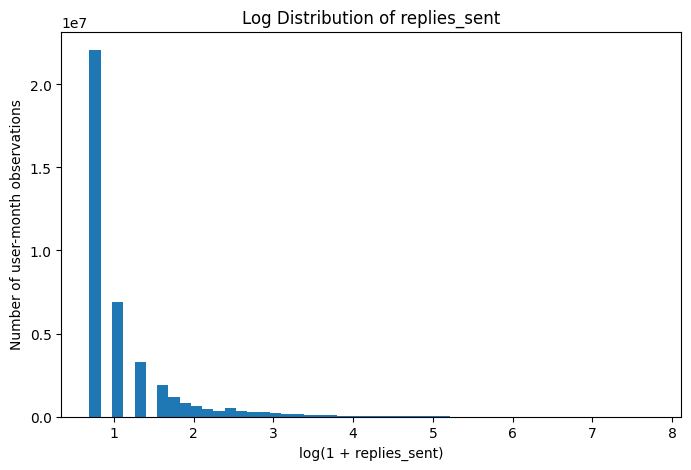

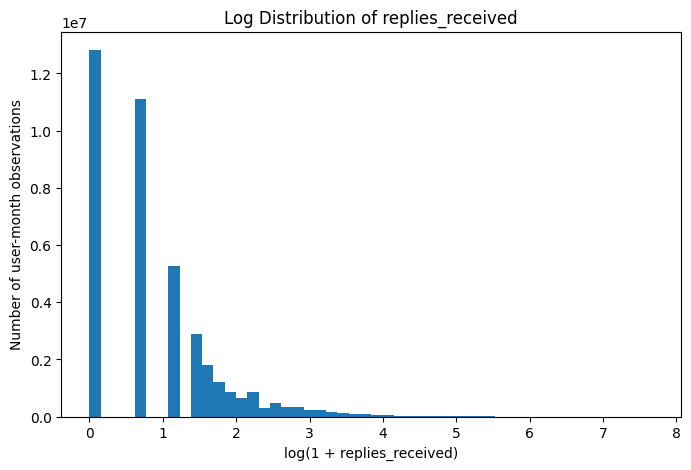

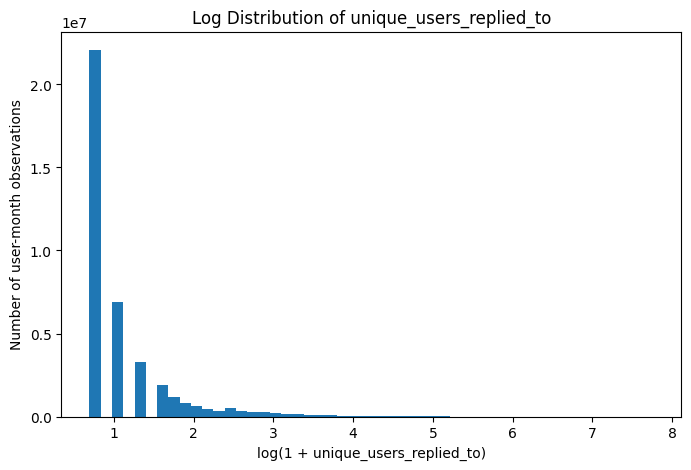

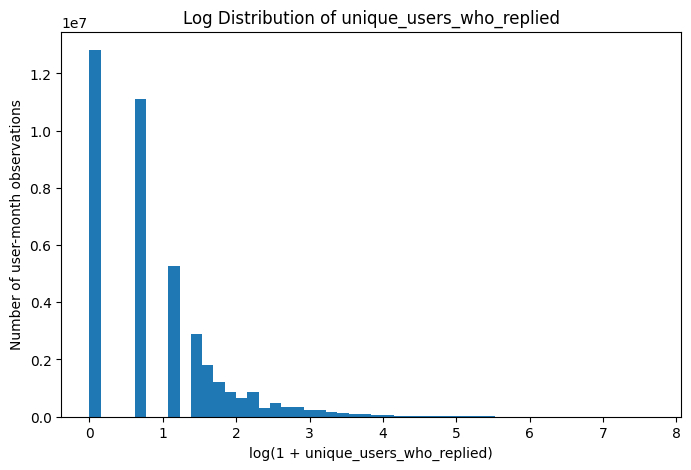

In [27]:
degree_plot_columns = [
    "replies_sent",
    "replies_received",
    "unique_users_replied_to",
    "unique_users_who_replied"
]

for column in degree_plot_columns:

    EdaPlots.histogram(
        np.log1p(activity_df[column]),
        xlabel=f"log(1 + {column})",
        ylabel="Number of user-month observations",
        title=f"Log Distribution of {column}"
    )

## Correlations / relationships

### User-level correlation matrix

In [28]:
correlation_columns = [
    "replies_sent",
    "replies_received",
    "unique_users_replied_to",
    "unique_users_who_replied",
    "total_interactions"
]

correlation_matrix = (
    activity_df[correlation_columns]
    .corr()
)

print("User-level correlation matrix")
print("=============================")
print(correlation_matrix.round(3))

User-level correlation matrix
                          replies_sent  replies_received  \
replies_sent                     1.000             0.868   
replies_received                 0.868             1.000   
unique_users_replied_to          1.000             0.868   
unique_users_who_replied         0.868             1.000   
total_interactions               0.965             0.968   

                          unique_users_replied_to  unique_users_who_replied  \
replies_sent                                1.000                     0.868   
replies_received                            0.868                     1.000   
unique_users_replied_to                     1.000                     0.868   
unique_users_who_replied                    0.868                     1.000   
total_interactions                          0.965                     0.968   

                          total_interactions  
replies_sent                           0.965  
replies_received                       0

### User-level correlation heatmap

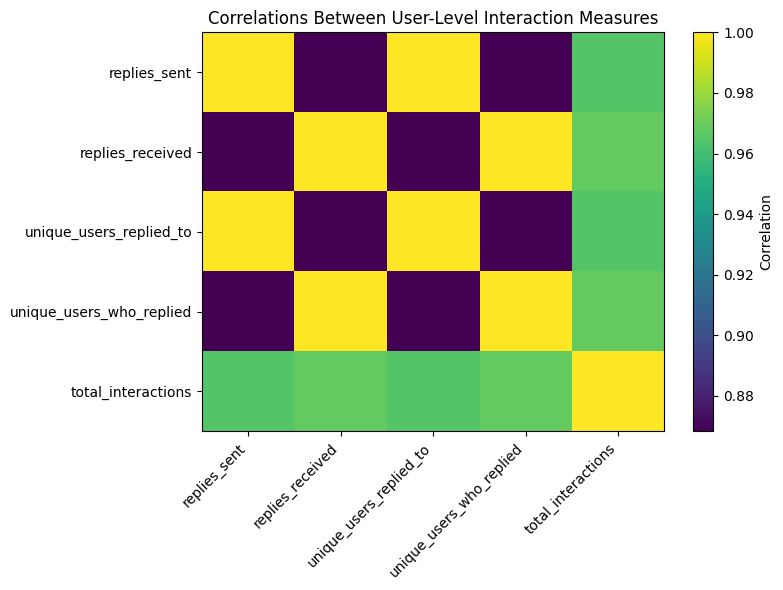

In [29]:
EdaPlots.correlation_heatmap(
    correlation_matrix,
    title="Correlations Between User-Level Interaction Measures"
)

### Replies sent vs replies received

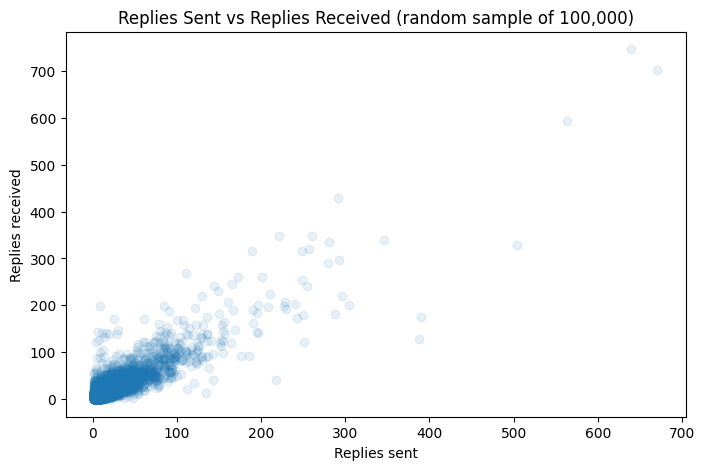

In [30]:
#random sample because plotting millions of points is very slow
scatter_sample = activity_df.sample(
    min(100000, len(activity_df)),
    random_state=1
)

EdaPlots.scatter(
    scatter_sample["replies_sent"],
    scatter_sample["replies_received"],
    xlabel="Replies sent",
    ylabel="Replies received",
    title="Replies Sent vs Replies Received (random sample of 100,000)",
    alpha=0.1
)

### Average return rate by number of replies sent

In [31]:
activity_numeric_return = EdaSummaries.return_rate_by(
    user_month_df,
    "replies_sent"
)

print(activity_numeric_return.head(20))

    replies_sent  observations  return_rate  return_rate_percent
0              1      19860469     0.222800            22.280028
1              2       6202752     0.368538            36.853787
2              3       2937100     0.477278            47.727759
3              4       1686490     0.559965            55.996537
4              5       1085141     0.623712            62.371249
5              6        752747     0.672433            67.243310
6              7        548988     0.712371            71.237076
7              8        415601     0.743186            74.318637
8              9        326552     0.768530            76.852997
9             10        261599     0.789307            78.930730
10            11        213778     0.807665            80.766496
11            12        177640     0.821256            82.125647
12            13        148899     0.833102            83.310163
13            14        127157     0.842321            84.232091
14            15        1

### Return rate for common activity levels

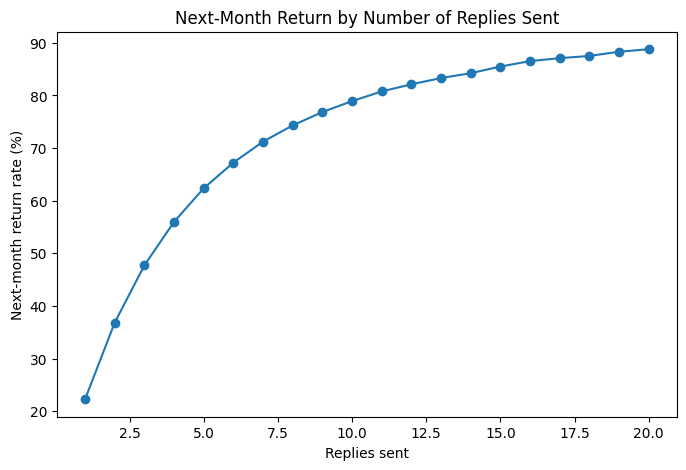

In [32]:
plot_activity_return = activity_numeric_return[
    activity_numeric_return["replies_sent"] <= 20
]

EdaPlots.line(
    plot_activity_return["replies_sent"],
    plot_activity_return["return_rate_percent"],
    xlabel="Replies sent",
    ylabel="Next-month return rate (%)",
    title="Next-Month Return by Number of Replies Sent"
)

## Community-level relationships

### Correlation matrix for network characteristics

In [33]:
community_correlation_columns = [
    "active_users",
    "edges",
    "density",
    "average_out_degree",
    "average_in_degree"
]

community_correlation_matrix = (
    community_df[community_correlation_columns]
    .corr()
)

print("Community-level correlation matrix")
print("==================================")
print(community_correlation_matrix.round(3))

Community-level correlation matrix
                    active_users  edges  density  average_out_degree  \
active_users               1.000  0.910   -0.074               0.072   
edges                      0.910  1.000   -0.066               0.224   
density                   -0.074 -0.066    1.000               0.337   
average_out_degree         0.072  0.224    0.337               1.000   
average_in_degree          0.072  0.224    0.337               1.000   

                    average_in_degree  
active_users                    0.072  
edges                           0.224  
density                         0.337  
average_out_degree              1.000  
average_in_degree               1.000  


### Community-level correlation heatmap

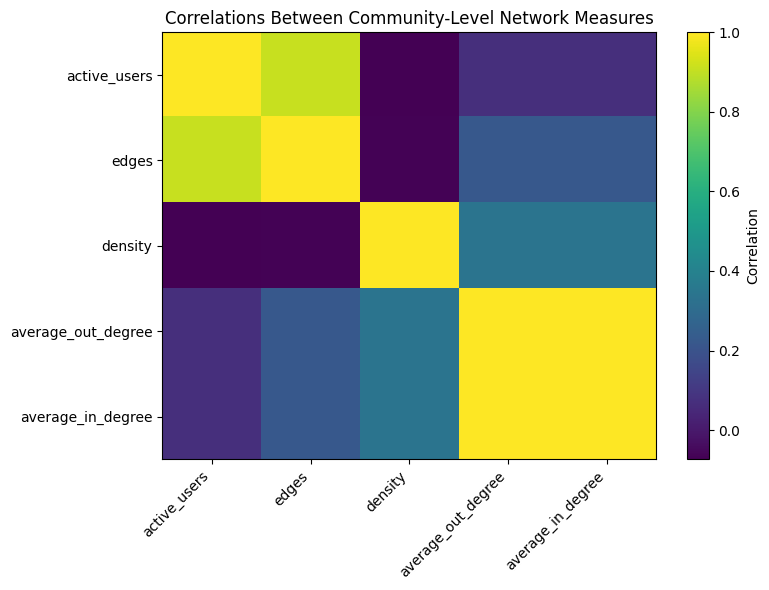

In [34]:
EdaPlots.correlation_heatmap(
    community_correlation_matrix,
    title="Correlations Between Community-Level Network Measures"
)

### Community characteristics and return rate

In [35]:
community_return_columns = [
    "active_users",
    "edges",
    "density",
    "average_out_degree",
    "average_in_degree",
    "return_rate"
]

community_return_correlations = (
    community_return_df[community_return_columns]
    .corr()["return_rate"]
    .sort_values(ascending=False)
)

print("Correlation with next-month return rate")
print("=======================================")
print(community_return_correlations.round(3))

Correlation with next-month return rate
return_rate           1.000
average_out_degree    0.689
average_in_degree     0.689
density               0.289
edges                 0.155
active_users          0.059
Name: return_rate, dtype: float64


## Across-subreddit comparison

### Average characteristics by subreddit (or load from csv)

In [36]:
subreddit_summary = datasets.subreddit_summary()

print("Number of subreddits:", len(subreddit_summary))
print(subreddit_summary.head())

Number of subreddits: 2046
       subreddit  observations  mean_replies_sent  median_replies_sent  \
0      2007scape         27995           5.759779                  2.0   
1          240sx          2140           3.117757                  2.0   
2  24hoursupport          2454           1.578647                  1.0   
3            3DS         39971           2.928398                  1.0   
4     3Dprinting         10471           3.277433                  2.0   

   mean_replies_received  median_replies_received  mean_total_interactions  \
0               5.485515                      2.0                11.245294   
1               2.800000                      2.0                 5.917757   
2               1.284026                      1.0                 2.862673   
3               2.606715                      1.0                 5.535113   
4               3.000096                      1.0                 6.277528   

   mean_active_users    mean_edges  mean_density  mean_out_

### Distribution of average replies sent across subreddits

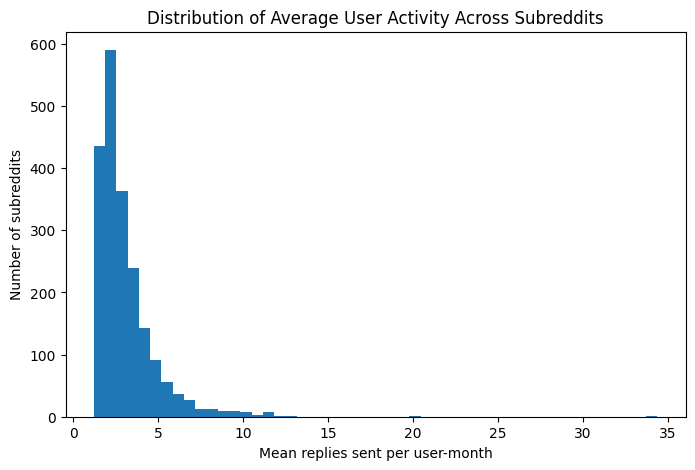

In [37]:
EdaPlots.histogram(
    subreddit_summary["mean_replies_sent"],
    xlabel="Mean replies sent per user-month",
    ylabel="Number of subreddits",
    title="Distribution of Average User Activity Across Subreddits"
)

### Distribution of subreddit return rates

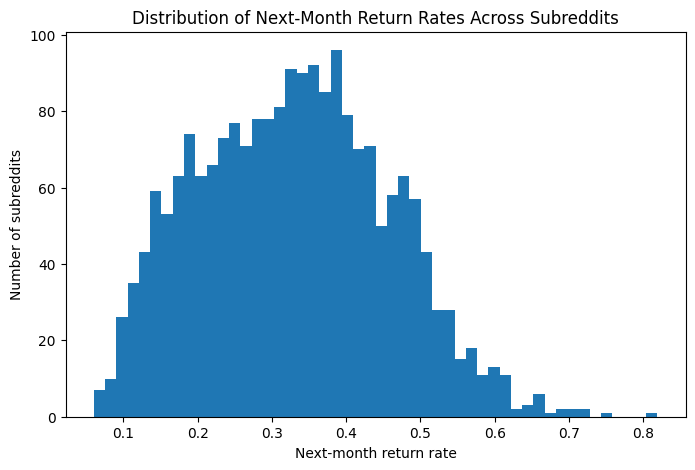

In [38]:
EdaPlots.histogram(
    subreddit_summary["return_rate"],
    xlabel="Next-month return rate",
    ylabel="Number of subreddits",
    title="Distribution of Next-Month Return Rates Across Subreddits"
)

### Smallest and largest subreddits by average community size

In [39]:
smallest_subreddits = (
    subreddit_summary
    .sort_values("mean_active_users")
    .head(10)
)

largest_subreddits = (
    subreddit_summary
    .sort_values("mean_active_users", ascending=False)
    .head(10)
)

print("Smallest subreddits")
print("===================")
print(
    smallest_subreddits[
        [
            "subreddit",
            "mean_active_users",
            "mean_replies_sent",
            "mean_density",
            "return_rate"
        ]
    ].to_string(index=False)
)

print("\nLargest subreddits")
print("==================")
print(
    largest_subreddits[
        [
            "subreddit",
            "mean_active_users",
            "mean_replies_sent",
            "mean_density",
            "return_rate"
        ]
    ].to_string(index=False)
)

Smallest subreddits
          subreddit  mean_active_users  mean_replies_sent  mean_density  return_rate
     ExploreFiction          20.363636           3.873303      0.203483     0.721951
  randomsuperpowers          28.727273          11.659091      0.344463     0.703846
               DWMA          32.454545          11.583569      0.361534     0.753943
      GLRP_EastBlue          33.545455           7.896175      0.234177     0.818991
     TheNarutoWorld          40.000000           5.474201      0.126544     0.642487
         HogwartsRP          54.090909           9.320236      0.143240     0.634989
     Musicthemetime          66.090909           3.438380      0.042041     0.528958
Argentinacirclejerk          70.636364           6.293447      0.083853     0.654459
     PJRP_Community          75.090909           7.445026      0.093710     0.656160
       workgonewild          76.818182           1.698682      0.014872     0.135776

Largest subreddits
      subreddit  mean_act

### Select representative smaller and larger subreddits

In [40]:
small_subreddits = (
    subreddit_summary
    .sort_values("mean_active_users")
    .head(5)["subreddit"]
    .tolist()
)

large_subreddits = (
    subreddit_summary
    .sort_values("mean_active_users", ascending=False)
    .head(5)["subreddit"]
    .tolist()
)

selected_subreddits = small_subreddits + large_subreddits

print("Selected subreddits:")
print(selected_subreddits)

Selected subreddits:
['ExploreFiction', 'randomsuperpowers', 'DWMA', 'GLRP_EastBlue', 'TheNarutoWorld', 'funny', 'pics', 'AdviceAnimals', 'videos', 'todayilearned']


### Compare average activity across selected subreddits

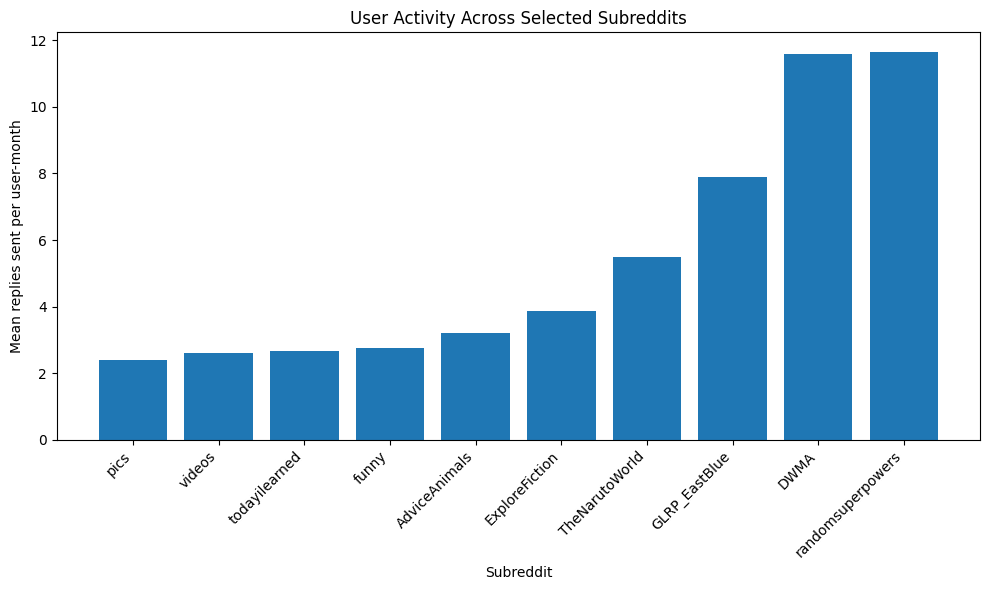

In [41]:
selected_summary = (
    subreddit_summary[
        subreddit_summary["subreddit"].isin(selected_subreddits)
    ]
    .copy()
    .sort_values("mean_replies_sent")
)

EdaPlots.bar(
    selected_summary["subreddit"],
    selected_summary["mean_replies_sent"],
    xlabel="Subreddit",
    ylabel="Mean replies sent per user-month",
    title="User Activity Across Selected Subreddits",
    figsize=(10, 6),
    rotate_labels=True
)

### Compare next-month return across selected subreddits

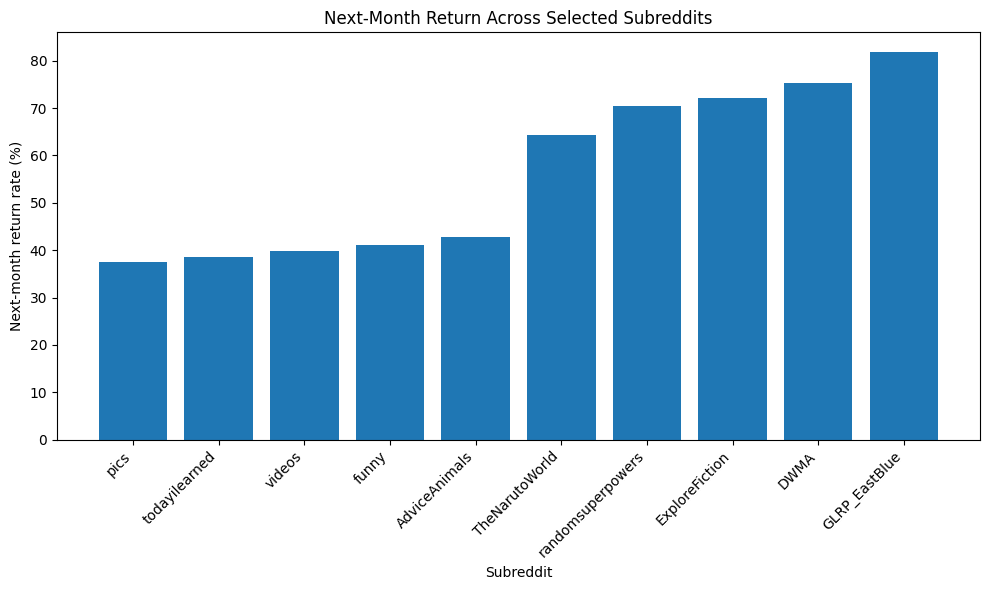

In [42]:
selected_return = (
    subreddit_summary[
        subreddit_summary["subreddit"].isin(selected_subreddits)
    ]
    .copy()
    .sort_values("return_rate")
)

EdaPlots.bar(
    selected_return["subreddit"],
    selected_return["return_rate"] * 100,
    xlabel="Subreddit",
    ylabel="Next-month return rate (%)",
    title="Next-Month Return Across Selected Subreddits",
    figsize=(10, 6),
    rotate_labels=True
)

In [43]:
# free memory: these datasets are not used below
del activity_df, return_df, user_month_df
datasets.release('user_activity', 'user_return', 'user_month')

## Reciprocity

Proportional reciprocity = reciprocal partners / outgoing partners (a candidate definition for the EDA, not necessarily the final EMM one).

### Build user-level reciprocity dataset (or load from csv)

In [44]:
reciprocity_df = datasets.user_reciprocity()

print("\nNumber of reciprocity observations:",
      f"{len(reciprocity_df):,}")

print(reciprocity_df.head())


Number of reciprocity observations: 40,050,308
   subreddit  month                user  reciprocal_partners  \
0  2007scape      1            ModReach                   12   
1  2007scape      1         cartman2468                    0   
2  2007scape      1  _CreativeNameHere_                    0   
3  2007scape      1           BigLou420                    0   
4  2007scape      1              Abstre                    2   

   outgoing_partners  proportional_reciprocity  
0                 27                  0.444444  
1                  1                  0.000000  
2                  1                  0.000000  
3                  1                  0.000000  
4                  3                  0.666667  


### Reciprocity summary statistics

In [45]:
print("Reciprocity summary statistics")
print("==============================")

print(
    reciprocity_df[
        [
            "reciprocal_partners",
            "outgoing_partners",
            "proportional_reciprocity"
        ]
    ]
    .describe()
    .map(lambda x: f"{x:,.3f}")
)

Reciprocity summary statistics


      reciprocal_partners outgoing_partners proportional_reciprocity
count      40,050,308.000    40,050,308.000           40,050,308.000
mean                1.438             3.416                    0.361
std                 4.754             8.961                    0.405
min                 0.000             1.000                    0.000
25%                 0.000             1.000                    0.000
50%                 1.000             1.000                    0.200
75%                 1.000             3.000                    0.667
max               816.000         2,350.000                    1.000


### Zero vs positive reciprocity

In [46]:
zero_reciprocity = (
    reciprocity_df["proportional_reciprocity"] == 0
).sum()

positive_reciprocity = (
    reciprocity_df["proportional_reciprocity"] > 0
).sum()

total_reciprocity_observations = len(reciprocity_df)

print("Reciprocity distribution")
print("========================")

print(
    "Zero reciprocity:",
    f"{zero_reciprocity:,}",
    f"({zero_reciprocity / total_reciprocity_observations * 100:.2f}%)"
)

print(
    "Positive reciprocity:",
    f"{positive_reciprocity:,}",
    f"({positive_reciprocity / total_reciprocity_observations * 100:.2f}%)"
)

Reciprocity distribution
Zero reciprocity: 19,150,192 (47.82%)
Positive reciprocity: 20,900,116 (52.18%)


### Distribution of proportional reciprocity

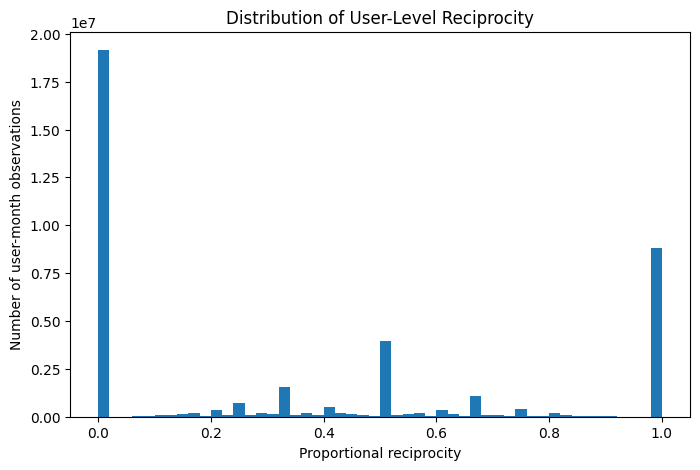

In [47]:
EdaPlots.histogram(
    reciprocity_df["proportional_reciprocity"],
    xlabel="Proportional reciprocity",
    ylabel="Number of user-month observations",
    title="Distribution of User-Level Reciprocity"
)

### Reciprocity over time

In [48]:
reciprocity_by_month = EdaSummaries.reciprocity_by(
    reciprocity_df,
    "month"
)

print(reciprocity_by_month)

    month  observations  mean_reciprocity  median_reciprocity
0       1       3427086          0.365295            0.230769
1       2       3418804          0.365159            0.250000
2       3       3461984          0.362199            0.222222
3       4       3502808          0.361342            0.200000
4       5       3482613          0.360101            0.200000
5       6       3535150          0.362833            0.222222
6       7       3737653          0.363608            0.250000
7       8       3754851          0.362105            0.222222
8       9       3828833          0.357890            0.200000
9      10       3881611          0.354291            0.200000
10     11       4018915          0.353814            0.200000


### Plot: reciprocity over time

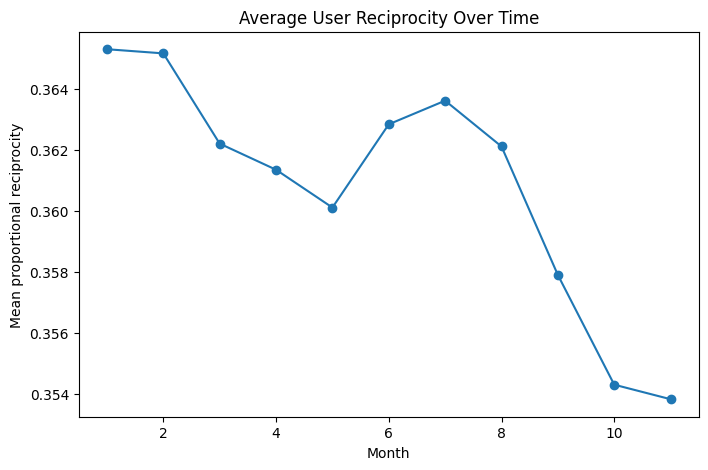

In [49]:
EdaPlots.line(
    reciprocity_by_month["month"],
    reciprocity_by_month["mean_reciprocity"],
    xlabel="Month",
    ylabel="Mean proportional reciprocity",
    title="Average User Reciprocity Over Time"
)

### Reciprocity by subreddit

In [50]:
reciprocity_by_subreddit = EdaSummaries.reciprocity_by(
    reciprocity_df,
    "subreddit"
)

print("Lowest mean reciprocity")
print("=======================")

print(
    reciprocity_by_subreddit
    .sort_values("mean_reciprocity")
    .head(10)
    .to_string(index=False)
)

print("\nHighest mean reciprocity")
print("========================")

print(
    reciprocity_by_subreddit
    .sort_values(
        "mean_reciprocity",
        ascending=False
    )
    .head(10)
    .to_string(index=False)
)

Lowest mean reciprocity
        subreddit  observations  mean_reciprocity  median_reciprocity
 photoshopbattles         63149          0.191813                 0.0
wheredidthesodago         16158          0.200006                 0.0
             gifs        431715          0.220672                 0.0
    NotTimAndEric          5510          0.228746                 0.0
           pornID          1861          0.231153                 0.0
         NSFW_GIF         18969          0.235089                 0.0
     thatHappened         44711          0.235465                 0.0
      TheSimpsons         17417          0.236661                 0.0
         pornvids          2643          0.236970                 0.0
  gentlemanboners         22516          0.237009                 0.0

Highest mean reciprocity
        subreddit  observations  mean_reciprocity  median_reciprocity
   ExploreFiction           221          0.951239            1.000000
       SVExchange         25229         

In [51]:
# free memory: these datasets are not used below
del reciprocity_df
datasets.release('user_reciprocity')

## Reciprocity & activity

### Merge reciprocity with user activity (or load from csv)

In [52]:
activity_reciprocity_df = datasets.user_activity_reciprocity()

print(
    "Number of observations:",
    f"{len(activity_reciprocity_df):,}"
)

Number of observations: 40,050,308


### Correlation between reciprocity and user activity

In [53]:
reciprocity_activity_columns = [
    "proportional_reciprocity",
    "replies_sent",
    "replies_received",
    "unique_users_replied_to",
    "unique_users_who_replied",
    "total_interactions"
]

reciprocity_activity_correlation = (
    activity_reciprocity_df[
        reciprocity_activity_columns
    ]
    .corr()
)

print("Reciprocity and activity correlations")
print("=====================================")

print(
    reciprocity_activity_correlation.round(3)
)

Reciprocity and activity correlations
                          proportional_reciprocity  replies_sent  \
proportional_reciprocity                     1.000         0.057   
replies_sent                                 0.057         1.000   
replies_received                             0.137         0.868   
unique_users_replied_to                      0.057         1.000   
unique_users_who_replied                     0.137         0.868   
total_interactions                           0.101         0.965   

                          replies_received  unique_users_replied_to  \
proportional_reciprocity             0.137                    0.057   
replies_sent                         0.868                    1.000   
replies_received                     1.000                    0.868   
unique_users_replied_to              0.868                    1.000   
unique_users_who_replied             1.000                    0.868   
total_interactions                   0.968                 

In [54]:
# free memory: these datasets are not used below
del activity_reciprocity_df
datasets.release('user_activity_reciprocity')

## Reciprocity & next-month return

### Merge reciprocity with next-month return (or load from csv)

In [55]:
reciprocity_return_df = datasets.reciprocity_return()

print(
    "Observations with reciprocity and return:",
    f"{len(reciprocity_return_df):,}"
)

Observations with reciprocity and return: 36,031,393


### Group users by proportional reciprocity

In [56]:
EdaSummaries.add_reciprocity_group(reciprocity_return_df)

reciprocity_return = EdaSummaries.return_rate_by(
    reciprocity_return_df,
    "reciprocity_group"
)

print(reciprocity_return)

  reciprocity_group  observations  return_rate  return_rate_percent
0                 0      17205902     0.276575            27.657469
1           >0–0.25       1550960     0.712082            71.208219
2        >0.25–0.50       6497359     0.540670            54.067045
3        >0.50–0.75       2402540     0.620140            62.014035
4           >0.75–1       8374632     0.268089            26.808856


### Plot: next-month return by reciprocity group

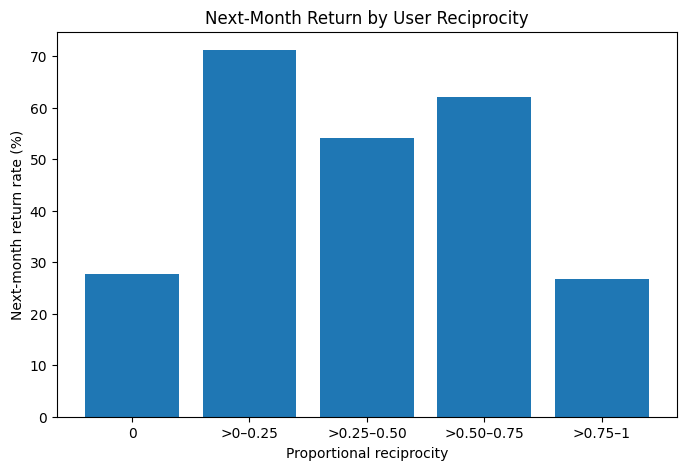

In [57]:
EdaPlots.bar(
    reciprocity_return["reciprocity_group"].astype(str),
    reciprocity_return["return_rate_percent"],
    xlabel="Proportional reciprocity",
    ylabel="Next-month return rate (%)",
    title="Next-Month Return by User Reciprocity"
)

### Activity and reciprocity together

In [58]:
EdaSummaries.add_activity_group(reciprocity_return_df)

activity_reciprocity_return = EdaSummaries.return_rate_by(
    reciprocity_return_df,
    ["activity_group", "reciprocity_group"]
)

print(activity_reciprocity_return)

   activity_group reciprocity_group  observations  return_rate  \
0         1 reply                 0      13521019     0.224251   
1         1 reply           >0.75–1       6339450     0.219707   
2     11+ replies                 0         11337     0.816089   
3     11+ replies           >0–0.25        306606     0.876522   
4     11+ replies        >0.25–0.50        932789     0.888927   
5     11+ replies        >0.50–0.75        569608     0.874709   
6     11+ replies           >0.75–1        133614     0.810170   
7     2–3 replies                 0       3141584     0.434012   
8     2–3 replies        >0.25–0.50       3782175     0.395201   
9     2–3 replies        >0.50–0.75        806700     0.441413   
10    2–3 replies           >0.75–1       1409393     0.335938   
11   4–10 replies                 0        531962     0.665245   
12   4–10 replies           >0–0.25       1244354     0.671565   
13   4–10 replies        >0.25–0.50       1782395     0.667096   
14   4–10 

## Setup. Keep only the subreddits the paper will actually analyse, and add helper columns

In [59]:
# use ALL subreddits (no minimum-observation filter)
df = EdaSummaries.analysis_sample(reciprocity_return_df)

print("subreddits in analysis sample:", df["subreddit"].nunique(), "(should be 2,046)")
print("rows in analysis sample:", len(df))
print("overall return rate:", round(df["returned_next_month"].mean(), 3))

subreddits in analysis sample: 2046 (should be 2,046)
rows in analysis sample: 36031393
overall return rate: 0.364


In [60]:
# free memory: these datasets are not used below
del reciprocity_return_df
datasets.release('reciprocity_return')

## Descriptive table (mean, spread, skewness, share of zeros) for the Data/EDA section

In [61]:
table = EdaSummaries.descriptive_table(df)

print(table.round(2).to_string())
table.round(3).to_csv(FIGURE_DIR / "descriptive_table.csv")
print(table.to_latex(float_format="%.2f"))          # paste-ready LaTeX table (needs Jinja2)

# how much of all activity comes from the most active 1% of user-months?
print("top 1% of user-months send", round(EdaSummaries.top_share(df["replies_sent"], 0.01), 1), "% of all replies")

# reciprocity is mostly 0 or 1 - how much exactly?
print("reciprocity == 0:", round((df["proportional_reciprocity"] == 0).mean() * 100, 1), "%")
print("reciprocity == 1:", round((df["proportional_reciprocity"] == 1).mean() * 100, 1), "%")
print("users with a single reply:", round((df["replies_sent"] == 1).mean() * 100, 1), "%")

                               Mean     SD  Median   P99     Max  Skewness  % zero
Variable                                                                          
Out-degree (replies sent)      3.41   8.94    1.00  35.0  2350.0     20.27    0.00
In-degree (replies received)   3.13   9.40    1.00  36.0  2173.0     17.85   31.99
Distinct partners (in or out)  5.10  13.39    2.00  53.0  2380.0     16.70    0.00
Reciprocal partners            1.44   4.75    1.00  17.0   816.0     19.57   47.75
Proportional reciprocity       0.36   0.41    0.21   1.0     1.0      0.57   47.75


\begin{tabular}{lrrrrrrr}
\toprule
 & Mean & SD & Median & P99 & Max & Skewness & % zero \\
Variable &  &  &  &  &  &  &  \\
\midrule
Out-degree (replies sent) & 3.41 & 8.94 & 1.00 & 35.00 & 2350.00 & 20.27 & 0.00 \\
In-degree (replies received) & 3.13 & 9.40 & 1.00 & 36.00 & 2173.00 & 17.85 & 31.99 \\
Distinct partners (in or out) & 5.10 & 13.39 & 2.00 & 53.00 & 2380.00 & 16.70 & 0.00 \\
Reciprocal partners & 1.44 & 4.75 & 1.00 & 17.00 & 816.00 & 19.57 & 47.75 \\
Proportional reciprocity & 0.36 & 0.41 & 0.21 & 1.00 & 1.00 & 0.57 & 47.75 \\
\bottomrule
\end{tabular}



top 1% of user-months send 19.8 % of all replies
reciprocity == 0: 47.8 %
reciprocity == 1: 22.1 %


users with a single reply: 55.1 %


## KEY figure. Return vs reciprocity, pooled and within activity level

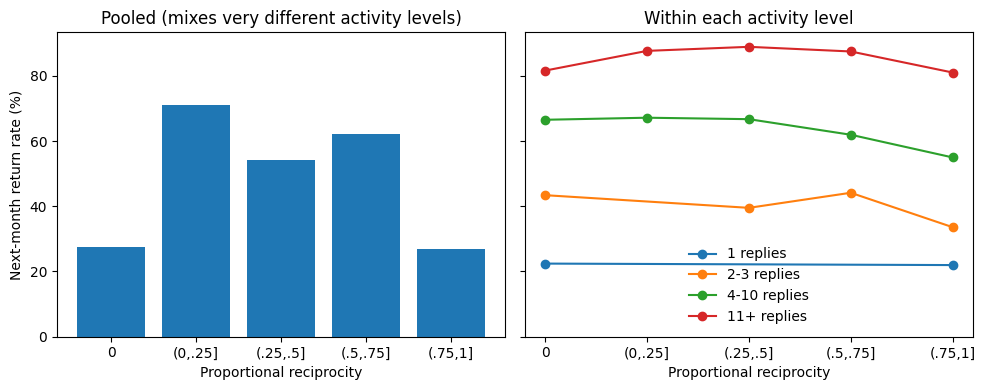

activity_group reciprocity_group        n  return_rate
             1                 0 13521019         22.4
             1           (.75,1]  6339450         22.0
           2-3                 0  3141584         43.4
           2-3          (.25,.5]  3782175         39.5
           2-3          (.5,.75]   806700         44.1
           2-3           (.75,1]  1409393         33.6
          4-10                 0   531962         66.5
          4-10           (0,.25]  1244354         67.2
          4-10          (.25,.5]  1782395         66.7
          4-10          (.5,.75]  1026232         61.9
          4-10           (.75,1]   492175         55.0
           11+                 0    11337         81.6
           11+           (0,.25]   306606         87.7
           11+          (.25,.5]   932789         88.9
           11+          (.5,.75]   569608         87.5
           11+           (.75,1]   133614         81.0


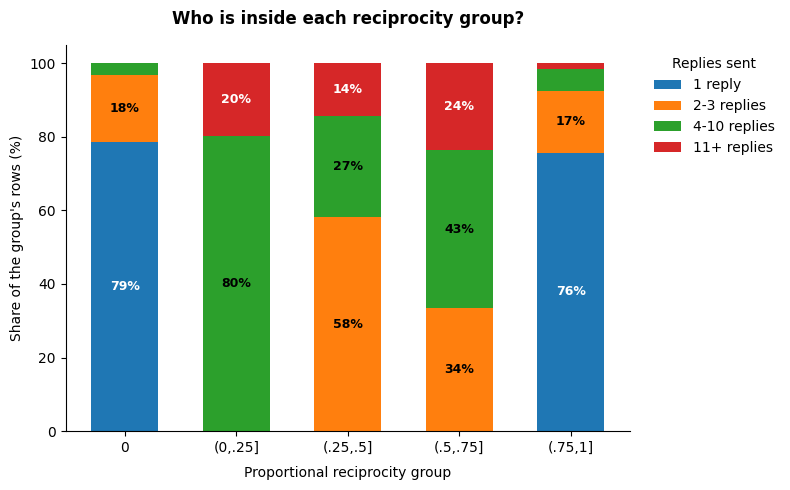

                          n  return_rate
reciprocity_group                       
0                  17205902         27.7
(0,.25]             1550960         71.2
(.25,.5]            6497359         54.1
(.5,.75]            2402540         62.0
(.75,1]             8374632         26.8


                       n  return_rate  share_pct
activity_group                                  
1               19860469         22.3       55.1
2-3              9139852         40.3       25.4
4-10             5077118         64.7       14.1
11+              1953954         87.7        5.4


activity_group        1   2-3  4-10   11+
reciprocity_group                        
0                  78.6  18.3   3.1   0.1
(0,.25]             0.0   0.0  80.2  19.8
(.25,.5]            0.0  58.2  27.4  14.4
(.5,.75]            0.0  33.6  42.7  23.7
(.75,1]            75.7  16.8   5.9   1.6


In [62]:
# return rate and group size for every (activity level, reciprocity level) combination
by_both = EdaSummaries.return_by_activity_and_reciprocity(df)
by_both.to_csv(FIGURE_DIR / "return_by_activity_and_reciprocity.csv", index=False)

# return rate by reciprocity only
pooled = df.groupby("reciprocity_group", observed=True)["returned_next_month"].mean()

# order of reciprocity groups, used to place points on the x-axis
group_order = list(df["reciprocity_group"].cat.categories)

EdaPlots.reciprocity_return(pooled, by_both, group_order)

# the numbers behind the figure
print(by_both.assign(return_rate=(by_both["return_rate"] * 100).round(1)).to_string(index=False))

# share of each activity level within each reciprocity group
plot_matrix = EdaSummaries.reciprocity_composition(by_both)

EdaPlots.reciprocity_composition(plot_matrix)

pooled = df.groupby("reciprocity_group", observed=True)["returned_next_month"].agg(n="size", return_rate="mean")
pooled["return_rate"] *= 100
print(pooled.round(1))

by_act = df.groupby("activity_group", observed=True)["returned_next_month"].agg(n="size", return_rate="mean")
by_act["return_rate"] *= 100
by_act["share_pct"] = by_act["n"] / by_act["n"].sum() * 100
print(by_act.round(1))

print((pd.crosstab(df["reciprocity_group"], df["activity_group"], normalize="index") * 100).round(1))

## Subreddits compared. Does the reciprocity-return link differ between communities? (motivates EMM)

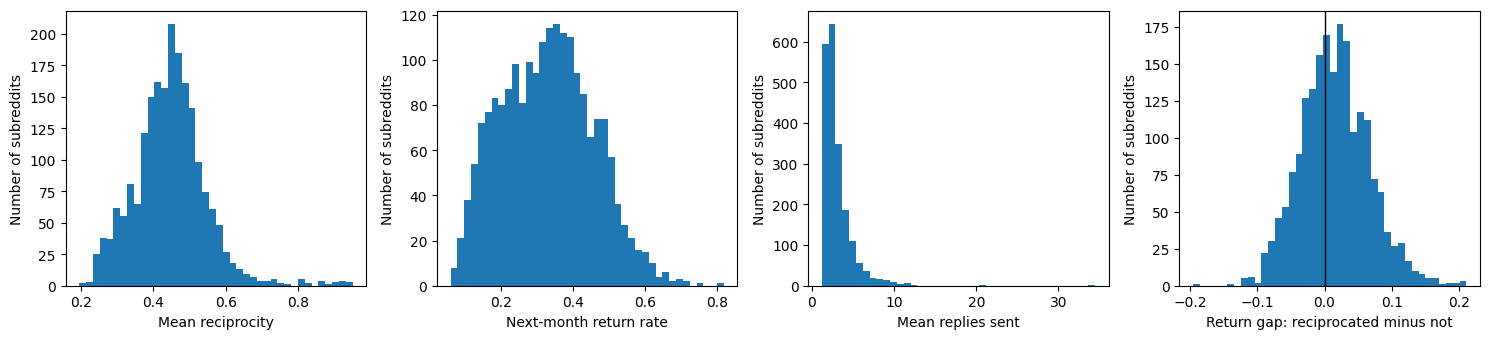

       mean_reciprocity  return_rate  mean_replies_sent  adjusted_gap
count          2046.000     2046.000           2046.000      2016.000
mean              0.447        0.329              3.047         0.015
std               0.100        0.128              1.829         0.051
min               0.196        0.060              1.207        -0.195
25%               0.387        0.229              1.955        -0.019
50%               0.445        0.329              2.526         0.014
75%               0.500        0.419              3.519         0.049
max               0.950        0.819             34.460         0.211
share of subreddits where reciprocated users return LESS: 38.7 %
share of subreddits where reciprocated users return MORE: 59.9 %
          subreddit       n  return_rate  mean_reciprocity  mean_replies_sent  adjusted_gap
     ExploreFiction     205        0.722             0.950              3.849           NaN
  randomsuperpowers     260        0.704             0.9

In [63]:
# one row per subreddit: size, return rate, average reciprocity, average activity,
# and the reciprocity-return gap (reciprocated minus not, activity held roughly fixed)
subs = EdaSummaries.subreddit_comparison(df)

# how much do subreddits differ?
EdaPlots.subreddit_spread(subs)

print(subs[["mean_reciprocity", "return_rate", "mean_replies_sent", "adjusted_gap"]].describe().round(3).to_string())
print("share of subreddits where reciprocated users return LESS:", round((subs["adjusted_gap"] < 0).mean() * 100, 1), "%")
print("share of subreddits where reciprocated users return MORE:", round((subs["adjusted_gap"] > 0).mean() * 100, 1), "%")

# representative subreddits: 3 smallest, 3 medium, 3 largest, lowest and highest reciprocity
representative = EdaSummaries.representative_subreddits(subs)
print(representative.round(3).to_string(index=False))
representative.round(4).to_csv(FIGURE_DIR / "representative_subreddits.csv", index=False)